# 02 — Unificación de datasets

Fase 2 del plan. Documenta cómo se pasa de tres datasets de detección (CODEBRIM, NEU-DET, RDD2022)
a un único dataset YOLO en `data/unified/`, y **justifica la taxonomía de clases elegida**.

Requiere haber ejecutado antes la conversión (`python -m src.data.unify`). Este notebook no escribe
nada en disco: lee `data/unified/` (salida de la conversión) y, para las estadísticas de descartes,
reutiliza las propias funciones de `src/data/unify.py`.

Contenido:
1. Esquema de clases y taxonomía unificada
2. Justificación: opción A (15 clases) frente a opción B (familias)
3. Qué se convierte y qué se descarta
4. Verificación de la salida (reparto, estratificación, cajas válidas)
5. Ejemplos visuales con las etiquetas ya convertidas
6. Tamaño de las cajas a la resolución de entrenamiento
7. Limitaciones y decisiones abiertas

## 0. Configuración

In [1]:
import sys
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import unify
from src.data.taxonomy import load_taxonomy
from src.utils.paths import load_paths, load_training_config

P, CFG, TAX = load_paths(), load_training_config(), load_taxonomy()
UNI = P["unified"]["root"]
IMG, LBL = P["unified"]["images"], P["unified"]["labels"]
SPLITS = unify.SPLITS
DATASETS = {"cb": "codebrim", "neu": "neu_surface", "rdd": "rdd2022"}

manifest = pd.read_csv(UNI / "manifest.csv")
dist = pd.read_csv(UNI / "class_distribution.csv")
print(f"{UNI}: {len(manifest)} imágenes, {int(dist.total.sum())} cajas, {len(dist)} clases")
print("split del config:", CFG["split"], "| semilla:", CFG["unify"]["seed"])

C:\Users\urkow\Documents\Github\inspectai-industrial-cv\data\unified: 11536 imágenes, 28918 cajas, 15 clases
split del config: {'train': 0.7, 'val': 0.1, 'test': 0.2} | semilla: 42


## 1. Esquema de clases y taxonomía unificada

Cada dataset describe los daños de forma distinta:

| Dataset | Esquema original |
|---|---|
| CODEBRIM | Un único `<name>` (`defect`) y, dentro de `<Defect>`, **seis flags** binarios: `Background`, `Crack`, `Spallation`, `Efflorescence`, `ExposedBars`, `CorrosionStain`. Multietiqueta |
| NEU-DET | Seis clases en `<name>`: `crazing`, `inclusion`, `patches`, `pitted_surface`, `rolled-in_scale`, `scratches` |
| RDD2022 | Siete clases en `<name>`: `D00`, `D10`, `D20`, `D40` (las del `label_map.pbtxt` oficial) y además `D43`, `D44`, `D50` |

La tabla siguiente es la taxonomía de `configs/taxonomy.yaml`, tal como la carga `src/data/taxonomy.py`.

In [2]:
classes = pd.DataFrame([asdict(c) for c in TAX.classes])
display(classes)
print("Familias declaradas:", TAX.families)

,id,name,dataset,source_label,family
0,0,concrete_crack,codebrim,Crack,grieta
1,1,concrete_spalling,codebrim,Spallation,fragmentacion
2,2,concrete_efflorescence,codebrim,Efflorescence,contaminacion
3,3,concrete_exposed_bars,codebrim,ExposedBars,corrosion
4,4,concrete_corrosion_stain,codebrim,CorrosionStain,corrosion
5,5,steel_crazing,neu_surface,crazing,grieta
6,6,steel_inclusion,neu_surface,inclusion,contaminacion
7,7,steel_patches,neu_surface,patches,contaminacion
8,8,steel_pitted_surface,neu_surface,pitted_surface,fragmentacion
9,9,steel_rolled_in_scale,neu_surface,rolled-in_scale,corrosion


Familias declaradas: ['grieta', 'fragmentacion', 'corrosion', 'deformacion', 'contaminacion']


## 2. Justificación: opción A frente a opción B

El plan plantea dos opciones:

- **Opción A:** mantener una clase por tipo de daño y dataset.
- **Opción B:** agrupar por tipo de daño morfológico (grieta, fragmentación, corrosión, deformación,
  contaminación) con independencia del material.

**Se ha elegido la opción A (15 clases)**, con la familia morfológica guardada como metadato. Las tablas
siguientes dan los argumentos con datos.

In [3]:
fam = dist.pivot_table(index="family", columns="dataset", values="total", aggfunc="sum", fill_value=0)
fam["total"] = fam.sum(axis=1)
fam["% del dataset mayoritario"] = (fam[["codebrim", "neu_surface", "rdd2022"]].max(axis=1) / fam["total"] * 100).round(1)
display(fam)

print(f"Número de clases   — opción A: {len(dist)} | opción B: {len(fam)}")
print(f"Clase mayor / menor — opción A: {dist.total.max() / dist.total.min():.1f} | opción B: {fam['total'].max() / fam['total'].min():.1f}")

dataset,codebrim,neu_surface,rdd2022,total,% del dataset mayoritario
family,,,,,
contaminacion,826,1892,0,2718,69.6
corrosion,3047,628,0,3675,82.9
deformacion,0,548,0,548,100.0
fragmentacion,1888,432,2243,4563,49.2
grieta,2499,689,14226,17414,81.7


Número de clases   — opción A: 15 | opción B: 5
Clase mayor / menor — opción A: 14.3 | opción B: 31.8


**Lectura de las tablas:**

1. **Agrupar no reduce el desbalance, lo empeora.** La proporción entre la clase mayor y la menor sube
   al agrupar, porque las familias grandes (grieta) absorben clases de varios datasets y las pequeñas
   (deformación) se quedan con una sola.
2. **Las familias están dominadas por un dominio.** La familia `grieta` sale en su mayor parte de
   RDD2022 (carretera): un modelo entrenado con ella aprendería sobre todo cómo se ve una grieta en
   asfalto, y la clase seguiría confundida con el dominio.
3. **Se pierde fidelidad con cada origen.** El `crazing` de una chapa de acero y una grieta de hormigón
   comparten nombre morfológico pero no apariencia; con la opción B un fallo del modelo sería difícil de
   interpretar (¿falla en acero o en hormigón?).
4. **La opción B sigue disponible.** La familia de cada clase está en `configs/taxonomy.yaml`, así que
   se puede entrenar más adelante con un mapeo de clases distinto sin reconvertir las imágenes.
5. **Asignaciones provisionales.** Las familias de `concrete_exposed_bars`, `steel_rolled_in_scale` y
   `steel_scratches` son las más discutibles, y `deformacion` solo contiene una clase. Es una razón más
   para no basar el entrenamiento en ellas todavía.

**Número de clases.** La primera versión del plan contaba 16 clases (6 + 6 + 4) y ya está corregido a 15.
Con los datos reales son 15: CODEBRIM aporta 5 daños (su sexto flag, `Background`, no es un daño) y RDD2022 aporta 4
(las del mapa oficial; D43, D44 y D50 se excluyen).

## 3. Qué se convierte y qué se descarta

`collect_all` es la misma función que usa la conversión. Ejecutarla de nuevo (solo lee, no escribe)
da los contadores de cada filtro.

In [4]:
samples, stats = unify.collect_all(P, TAX, CFG, limit=0)
stats_df = pd.DataFrame(stats).fillna(0).astype(int)
display(stats_df)
print(f"Imágenes que pasan a data/unified: {len(samples)} (el manifest tiene {len(manifest)})")

,codebrim,neu_surface,rdd2022
imagenes_origen,1590,1800,10506
objetos_origen,5233,0,0
imagenes_ok,1042,1800,8694
imagenes_negativas,26,0,794
cajas_ok,8260,4189,16469
imagenes_descartadas_tamano_incoherente,10,0,0
objetos_sin_clase_de_dano,52,0,0
imagenes_sin_xml_descartadas,538,0,0
imagenes_solo_clase_excluida,0,0,1812
cajas_clase_excluida,0,0,8284


Imágenes que pasan a data/unified: 11536 (el manifest tiene 11536)


Cómo leer los contadores:

- `imagenes_origen`: imágenes en `data/raw`.
- `imagenes_sin_xml_descartadas` (CODEBRIM): sin anotación. No se sabe si están limpias, así que **no se
  usan como negativas**.
- `imagenes_descartadas_tamano_incoherente` (CODEBRIM): el XML declara otro tamaño que el fichero y las
  cajas no se pueden mapear.
- `objetos_sin_clase_de_dano` (CODEBRIM): objetos que solo tienen el flag `Background` o ninguno; no generan caja.
- `cajas_clase_excluida` / `imagenes_solo_clase_excluida` (RDD2022): D43, D44 y D50. Las imágenes que solo
  tienen esas cajas se descartan.
- `imagenes_negativas`: anotadas que se quedan sin cajas; se conservan con etiqueta vacía.
- `cajas_descartadas_tamano`: cajas menores de `unify.min_box_px` píxeles.

### CODEBRIM es multietiqueta; YOLO no

Cada objeto genera una caja por flag activo, con las mismas coordenadas. Se comprueba leyendo las
etiquetas ya escritas: se agrupan las cajas idénticas de cada imagen.

In [5]:
rows = []
for split in SPLITS:
    for f in (LBL / split).glob("*.txt"):
        for line in f.read_text().splitlines():
            c, cx, cy, w, h = line.split()
            rows.append((split, f.stem, int(c), float(cx), float(cy), float(w), float(h)))
boxes = pd.DataFrame(rows, columns=["split", "image", "cls", "cx", "cy", "w", "h"])
boxes["dataset"] = boxes.image.str.split("_").str[0].map(DATASETS)
boxes["clase"] = boxes.cls.map(dict(enumerate(TAX.names)))
print(len(boxes), "cajas leídas de", boxes.image.nunique(), "ficheros de etiquetas con al menos una caja")

cb = boxes[boxes.dataset == "codebrim"]
per_object = cb.groupby(["image", "cx", "cy", "w", "h"]).size()
print("\nObjetos de CODEBRIM según el número de clases activas:")
print(per_object.value_counts().sort_index().rename("objetos"))
print(f"\n% de objetos con más de una clase: {(per_object > 1).mean():.1%} | "
      f"cajas YOLO por objeto: {len(cb) / len(per_object):.2f}")

28918 cajas leídas de 10716 ficheros de etiquetas con al menos una caja

Objetos de CODEBRIM según el número de clases activas:
1    3198
2     980
3     896
4      86
5      14
Name: objetos, dtype: int64

% de objetos con más de una clase: 38.2% | cajas YOLO por objeto: 1.60


Las cajas duplicadas con clases distintas son válidas en YOLO y permiten predecir varias clases sobre
el mismo objeto, pero compiten por las mismas posiciones de predicción: el aprendizaje de esas zonas
es algo menos limpio. Si en la fase 3 las clases de CODEBRIM rinden claramente peor que las de los
otros datasets, esta es una de las causas a revisar.

## 4. Verificación de la salida

In [6]:
pivot = manifest.pivot_table(index="dataset", columns="split", values="image", aggfunc="count")[list(SPLITS)]
pivot["total"] = pivot.sum(axis=1)
pivot.loc["TOTAL"] = pivot.sum()
display(pivot)

share = pivot.drop(columns="total").div(pivot["total"], axis=0).round(3)
print("Proporción por split y dataset (objetivo:", CFG["split"], ")")
display(share)

neg = manifest[manifest.n_boxes == 0].groupby("split").size().reindex(list(SPLITS)).fillna(0).astype(int)
print("Imágenes negativas por split:", neg.to_dict(), f"| {neg.sum() / len(manifest):.1%} del total")

missing = [r.image for r in manifest.itertuples()
           if not ((IMG / r.split / f"{r.image}.jpg").exists() and (LBL / r.split / f"{r.image}.txt").exists())]
print("Filas del manifest sin imagen o sin etiqueta:", len(missing))

eps = 1e-6
bad = boxes[(boxes.w <= 0) | (boxes.h <= 0) | (boxes.cx - boxes.w / 2 < -eps) | (boxes.cx + boxes.w / 2 > 1 + eps)
            | (boxes.cy - boxes.h / 2 < -eps) | (boxes.cy + boxes.h / 2 > 1 + eps)]
print("Cajas fuera de rango o degeneradas:", len(bad))
print("Ids de clase presentes:", sorted(boxes.cls.unique()), "| esperados: 0 a", len(TAX.classes) - 1)

split,train,val,test,total
dataset,,,,
codebrim,730,104,208,1042
neu_surface,1260,180,360,1800
rdd2022,6087,869,1738,8694
TOTAL,8077,1153,2306,11536


Proporción por split y dataset (objetivo: {'train': 0.7, 'val': 0.1, 'test': 0.2} )


split,train,val,test
dataset,,,
codebrim,0.701,0.1,0.2
neu_surface,0.700,0.1,0.2
rdd2022,0.700,0.1,0.2
TOTAL,0.700,0.1,0.2


Imágenes negativas por split: {'train': 574, 'val': 82, 'test': 164} | 7.1% del total
Filas del manifest sin imagen o sin etiqueta: 0
Cajas fuera de rango o degeneradas: 0
Ids de clase presentes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | esperados: 0 a 14


### Estratificación por clase

Si el reparto estratificado funciona, cada clase debería repartirse en las proporciones de `split`
(70 / 10 / 20) con desviaciones pequeñas, incluidas las clases minoritarias.

,train,val,test,desv. máx. (pp),cajas
name,,,,,
concrete_crack,68.1,8.8,23.0,3.0,2499
concrete_spalling,69.4,11.2,19.4,1.2,1888
concrete_efflorescence,70.5,7.9,21.7,2.1,826
concrete_exposed_bars,69.9,12.6,17.5,2.6,1500
concrete_corrosion_stain,72.1,10.3,17.6,2.4,1547
steel_crazing,69.8,10.6,19.6,0.6,689
steel_inclusion,70.2,9.4,20.4,0.6,1011
steel_patches,70.0,10.7,19.3,0.7,881
steel_pitted_surface,71.3,10.9,17.8,2.2,432


Desviación máxima en puntos porcentuales: 3.0


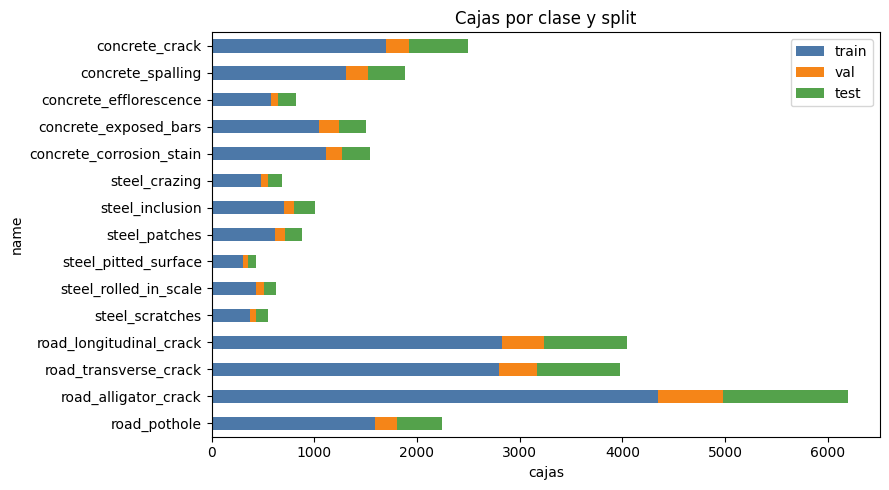

In [7]:
counts = dist.set_index("name")[list(SPLITS)]
class_share = counts.div(counts.sum(axis=1), axis=0)
target = pd.Series(CFG["split"])[list(SPLITS)]
report = (class_share * 100).round(1)
report["desv. máx. (pp)"] = ((class_share - target).abs().max(axis=1) * 100).round(1)
report["cajas"] = counts.sum(axis=1)
display(report)
print("Desviación máxima en puntos porcentuales:", report["desv. máx. (pp)"].max())

fig, ax = plt.subplots(figsize=(9, 5))
counts.plot.barh(stacked=True, ax=ax, color=["#4c78a8", "#f58518", "#54a24b"])
ax.invert_yaxis()
ax.set_xlabel("cajas")
ax.set_title("Cajas por clase y split")
plt.tight_layout()
plt.show()

## 5. Ejemplos visuales con las etiquetas ya convertidas

Imágenes de `data/unified/test` con varias cajas, dibujadas a partir de los ficheros `.txt` (no del XML
original), de modo que se valida toda la cadena: conversión, reescalado y coordenadas normalizadas.
Debajo, imágenes negativas (etiqueta vacía).

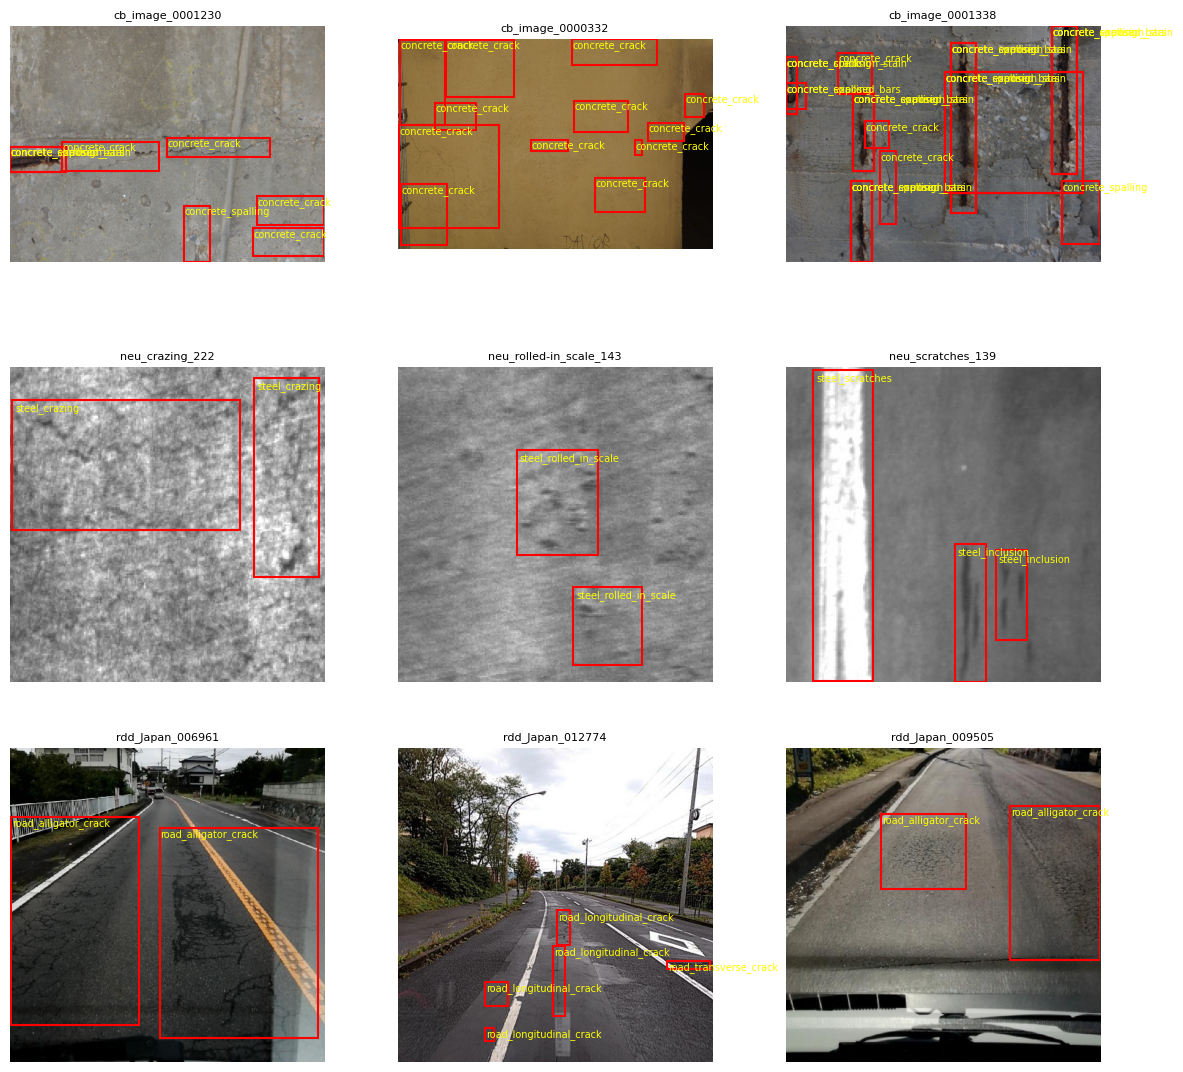

In [8]:
def draw(ax, split, name):
    im = Image.open(IMG / split / f"{name}.jpg")
    W, H = im.size
    ax.imshow(im, cmap="gray" if im.mode == "L" else None)
    for b in boxes[(boxes.split == split) & (boxes.image == name)].itertuples():
        x0, y0 = (b.cx - b.w / 2) * W, (b.cy - b.h / 2) * H
        ax.add_patch(Rectangle((x0, y0), b.w * W, b.h * H, fill=False, color="red", lw=1.5))
        ax.text(x0 + 2, y0 + 2, b.clase, color="yellow", fontsize=7, va="top")
    ax.set_title(name, fontsize=8)
    ax.axis("off")


rng = np.random.default_rng(CFG["unify"]["seed"])
fig, axes = plt.subplots(len(DATASETS), 3, figsize=(12, 3.8 * len(DATASETS)))
for row, (prefix, dataset) in enumerate(DATASETS.items()):
    multi = boxes[(boxes.split == "test") & (boxes.dataset == dataset)].groupby("image").size()
    pool = multi[multi >= 2].index.tolist()
    for col, name in enumerate(rng.choice(pool, size=3, replace=False)):
        draw(axes[row, col], "test", name)
plt.tight_layout()
plt.show()

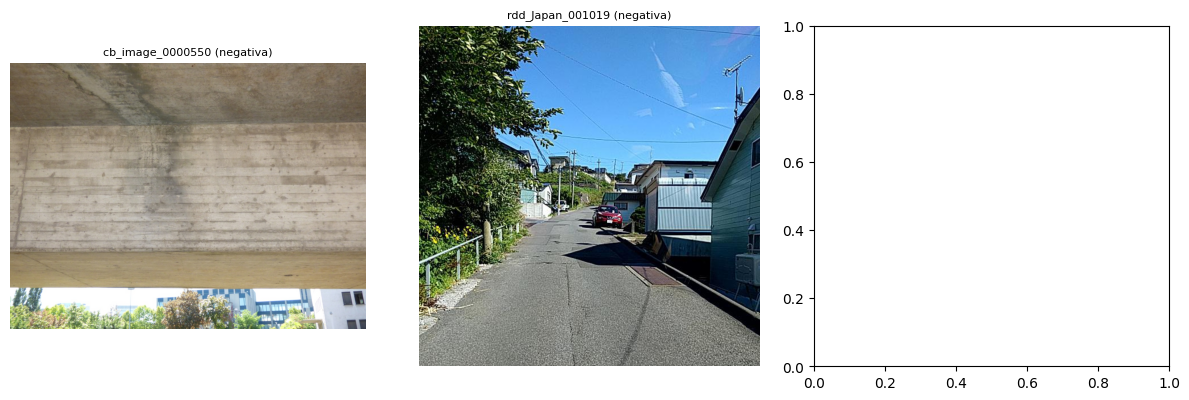

Datasets con negativas: ['codebrim', 'rdd2022']


In [9]:
neg_rows = manifest[(manifest.n_boxes == 0) & (manifest.split == "train")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, name in zip(axes, neg_rows.groupby("dataset").head(1).image.tolist()[:3]):
    draw(ax, "train", name)
    ax.set_title(f"{name} (negativa)", fontsize=8)
plt.tight_layout()
plt.show()
print("Datasets con negativas:", sorted(neg_rows.dataset.unique()))

## 6. Tamaño de las cajas a la resolución de entrenamiento

`training_config.yaml` fija `supervised.imgsz = 640`. Ultralytics reduce cada imagen hasta que su lado mayor
mide 640 píxeles, así que una caja de ancho normalizado `w` mide en torno a `w · ancho_salida · 640 / lado_mayor`.
Las imágenes pequeñas (las de NEU, de 200 px) se amplían hasta ese tamaño. Las cajas muy pequeñas a esa
resolución son las que más fallará el modelo; esta tabla ayuda a decidir en la fase 3 si merece la
pena probar 1280 px. Es una estimación: el aumento de datos de YOLO (mosaico, escalado) la modifica
durante el entrenamiento.

,cajas,mediana_w_px,mediana_h_px,pct_menor_16px,pct_menor_32px
clase,,,,,
concrete_crack,2499,68.3,62.3,8.3,36.6
concrete_spalling,1888,95.2,91.9,2.4,17.4
concrete_efflorescence,826,95.3,96.0,2.9,19.0
concrete_exposed_bars,1500,83.4,88.2,4.5,22.2
concrete_corrosion_stain,1547,78.8,90.7,5.6,23.8
steel_crazing,689,403.2,224.0,0.0,0.0
steel_inclusion,1011,80.0,208.0,0.0,0.0
steel_patches,881,166.4,230.4,0.0,0.0
steel_pitted_surface,432,400.0,611.2,0.0,0.0


C:\Users\urkow\AppData\Local\Temp\ipykernel_10388\3490297389.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, vert=False, labels=TAX.names, showfliers=False)


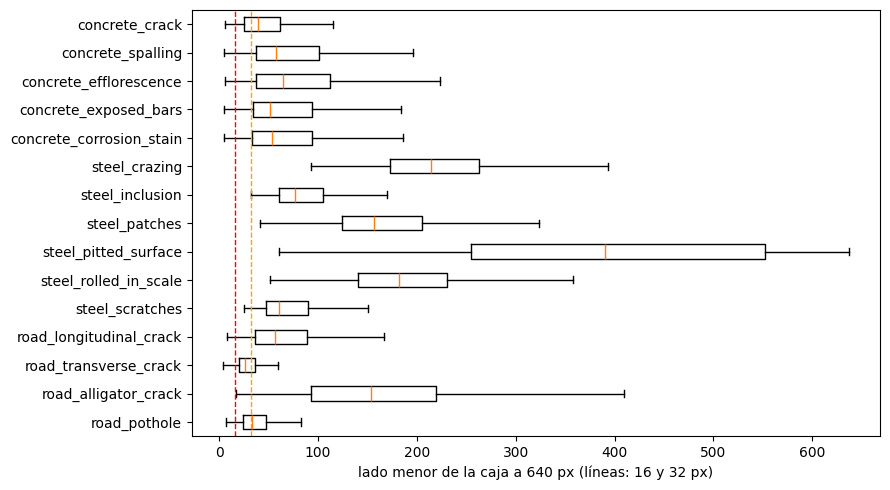

In [10]:
imgsz = CFG["supervised"]["imgsz"]
size = boxes.merge(manifest[["image", "out_w", "out_h"]], on="image")
scale = imgsz / size[["out_w", "out_h"]].max(axis=1)
size["w_px"], size["h_px"] = size.w * size.out_w * scale, size.h * size.out_h * scale
size["lado_min_px"] = size[["w_px", "h_px"]].min(axis=1)

summary = size.groupby("clase").agg(cajas=("cls", "size"),
                                    mediana_w_px=("w_px", "median"), mediana_h_px=("h_px", "median"),
                                    pct_menor_16px=("lado_min_px", lambda s: (s < 16).mean() * 100),
                                    pct_menor_32px=("lado_min_px", lambda s: (s < 32).mean() * 100))
summary = summary.reindex(TAX.names).round(1)
display(summary)

fig, ax = plt.subplots(figsize=(9, 5))
data = [size.loc[size.clase == n, "lado_min_px"].clip(upper=640) for n in TAX.names]
ax.boxplot(data, vert=False, labels=TAX.names, showfliers=False)
ax.axvline(16, color="red", ls="--", lw=1)
ax.axvline(32, color="orange", ls="--", lw=1)
ax.set_xlabel(f"lado menor de la caja a {imgsz} px (líneas: 16 y 32 px)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Limitaciones y decisiones abiertas

- **Imágenes casi idénticas en splits distintos.** Los datasets no indican escena u objeto fotografiado y la
  numeración de ficheros no agrupa imágenes parecidas (la correlación entre imágenes consecutivas es igual
  que entre imágenes al azar en RDD2022). Los resultados de test pueden ser algo optimistas.
- **Desbalance.** La proporción entre la clase mayor y la menor es de unas 14 a 1; habrá que valorar
  pesos de pérdida o sobremuestreo en la fase 3.
- **Desbalance entre dominios.** RDD2022 aporta el 57 % de las cajas; conviene mirar las métricas por
  dataset y no solo las globales.
- **Cajas duplicadas en CODEBRIM** (sección 3): válidas, pero pueden afectar al aprendizaje de esas clases.
- **Familias morfológicas provisionales** (sección 2).
- **Sin test con etiquetas de origen.** Todo el reparto es aleatorio estratificado; las 2.627 imágenes de
  `RDD2022/Japan/test` no tienen anotaciones y no se usan.
- **Licencias.** CODEBRIM solo permite uso no comercial y no permite redistribuir los datos ni versiones
  modificadas, lo que incluye `data/unified/`. Ver `DATA_CARD.md`.

Decisión pendiente para la fase 3: si el modelo rinde mal con las clases pequeñas, comparar `imgsz=640`
frente a `imgsz=1280` con la tabla de la sección 6.